<a href="https://colab.research.google.com/github/Ravpalz/RaffiAbbad_123240147_IF_H_UTSDataScience/blob/main/RaffiAbbad_123240147_IF_H_UTSDataScience.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nama: Raffi Abbad Vega Pratama

NIM: 123240147

Kelas: IF-H

# Phase 1 — Business Understanding

## Client Context

**InnovateGlobe Corp.** ingin meluncurkan produk atau layanan yang **ethical** dan **commercially viable**, selaras dengan **UN Sustainable Development Goals (SDGs)**. Mereka menyediakan data **World Values Survey (WVS) Wave 7** untuk menggali sikap publik, nilai konsumen, prioritas sosial, dan perbedaan regional.

## SDG Anchor

Proyek ini berfokus pada dua SDG yang saling terkait.

**Goal 16 — Peace, Justice and Strong Institutions**

- **Target 16.5**: substantially reduce corruption and bribery in all their forms. Relevansi: inti produk adalah platform anti-korupsi.
- **Target 16.6**: develop effective, accountable and transparent institutions at all levels. Relevansi: nilai yang ditawarkan adalah transparansi dan akuntabilitas.
- **Target 16.7**: ensure responsive, inclusive, participatory and representative decision-making. Relevansi: partisipasi publik dalam pelaporan.
- **Target 16.10**: ensure public access to information and protect fundamental freedoms. Relevansi: akses informasi dan perlindungan pelapor.

**Goal 10 — Reduced Inequalities**

- **Target 10.2**: empower and promote the social, economic and political inclusion of all. Relevansi: desain inklusif lintas gender, usia, wilayah, dan pendidikan.
- **Target 10.3**: ensure equal opportunity and reduce inequalities of outcome. Relevansi: akses keadilan tanpa diskriminasi.

## Business Question

> **Segmen demografis dan nilai-nilai sosial mana yang memiliki persepsi korupsi tinggi, kepercayaan institusi rendah, namun menunjukkan potensi partisipasi sipil tinggi — dan bagaimana profil tersebut dapat digunakan untuk merancang strategi peluncuran civic-tech anti-corruption platform yang inklusif?**

**Sub-questions**

1. Bagaimana distribusi persepsi korupsi (**Q112**) dan kepercayaan institusi (**Q69–Q74**) antar negara dan kelompok demografis?
2. Apakah ada korelasi antara persepsi korupsi, ketimpangan yang dirasakan (**Q106**, **Q110**), dan kepercayaan institusi?
3. Segmen atau persona apa yang muncul dari clustering berdasarkan nilai, persepsi, dan demografi?
4. Faktor apa yang paling memprediksi potensi adopsi platform (partisipasi sipil tinggi dan persepsi korupsi tinggi)?
5. Kanal informasi apa (**Q201–Q207**) yang paling efektif untuk menjangkau persona target?

## Success Criteria

**Business Perspective**

- Menghasilkan minimal satu target persona yang actionable (demografi, nilai, dan kanal).
- Mengidentifikasi minimal satu prioritas region atau negara untuk peluncuran.
- Memberikan rekomendasi desain produk yang inklusif (Goal 10) dan transparan (Goal 16).
- Insight dapat diterjemahkan langsung ke **product spec** dan **go-to-market strategy**.

**Data Science Perspective**

- **Data quality**: missing value rate terdokumentasi; kode negatif WVS ditangani eksplisit.
- **Index validity**: Cronbach's alpha ≥ 0.70.
- **Clustering**: silhouette score ≥ 0.3 dan interpretable.
- **Classification**: ROC-AUC ≥ 0.70 pada test set dengan stratifikasi per negara.
- **Reproducibility**: pipeline terdokumentasi, random seed ditetapkan, **W_WEIGHT** dipertimbangkan.

## Definisi Variabel Kunci

- **Persepsi korupsi**: Q112, Q113–Q117.
- **Pengalaman suap**: Q118, Q120.
- **Kepercayaan institusi**: Q69–Q74.
- **Kepuasan sistem politik**: Q252.
- **Ketimpangan yang dirasakan**: Q106, Q110, Q287, Q288.
- **Partisipasi sipil**: Q209–Q216.
- **Aksi politik online**: Q217–Q220.
- **Perilaku memilih**: Q221, Q222.
- **Minat dan sumber informasi**: Q199–Q207.
- **Demografi**: Q260, Q262, Q275, Q279, Q288, Q289, Q290, H_URBURAL.
- **Bobot survei**: W_WEIGHT.

In [ ]:
# =========================================================
# CELL 1: Setup
# =========================================================
!pip install -q pandas numpy matplotlib seaborn scikit-learn scipy

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, roc_auc_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 6)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Setup selesai ✅")

Setup selesai ✅


In [ ]:
# =========================================================
# CELL 2: Load Data
# =========================================================
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = "/content/drive/MyDrive/Dataset/WVS_Cross-National_Wave_7_csv_v6_0.csv"
df_raw = pd.read_csv(DATA_PATH, low_memory=False)

print("Shape:", df_raw.shape)
print("Kolom pertama:", df_raw.columns[:6].tolist())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape: (97220, 613)
Kolom pertama: ['version', 'doi', 'A_WAVE', 'A_YEAR', 'A_STUDY', 'B_COUNTRY']


In [ ]:
# =========================================================
# CELL 3: Pilih Negara Fokus
# =========================================================
# Default: 5 negara dengan n >= 1000 dan coverage Q112-Q120 terbaik.
# Override manual: isi FOCUS_COUNTRIES dengan list kode B_COUNTRY.

NEG = [-1, -2, -3, -4, -5]
CORRUPTION_VARS = [c for c in ["Q112","Q113","Q114","Q115","Q116","Q117","Q118","Q120"] if c in df_raw.columns]

def compute_coverage(df, vars_):
    rows = []
    for code, g in df.groupby("B_COUNTRY"):
        n = len(g)
        if n < 1000:
            continue
        miss = g[vars_].isin(NEG).mean().mean() * 100
        alpha = g["B_COUNTRY_ALPHA"].iloc[0] if "B_COUNTRY_ALPHA" in g.columns else str(code)
        rows.append((code, alpha, n, round(miss, 1)))
    return pd.DataFrame(rows, columns=["B_COUNTRY","alpha","n","miss_pct"]).sort_values("miss_pct").reset_index(drop=True)

cov = compute_coverage(df_raw, CORRUPTION_VARS)
print("20 negara dengan coverage terbaik:")
print(cov.head(20).to_string(index=False))

FOCUS_COUNTRIES = cov.head(5)["B_COUNTRY"].tolist()
COUNTRY_LABELS = dict(zip(cov.head(5)["B_COUNTRY"], cov.head(5)["alpha"]))
print("\nFOCUS_COUNTRIES (auto):", FOCUS_COUNTRIES)
print("Label:", COUNTRY_LABELS)

20 negara dengan coverage terbaik:
 B_COUNTRY alpha    n  miss_pct
       104   MMR 1200       0.0
       124   CAN 4018       0.0
       170   COL 1520       0.0
       410   KOR 1245       0.0
       496   MNG 1638       0.0
       504   MAR 1200       0.0
       458   MYS 1313       0.0
       608   PHL 1200       0.2
       558   NIC 1200       0.3
       862   VEN 1190       0.4
       462   MDV 1039       0.7
       840   USA 2596       0.9
       422   LBN 1200       1.0
       630   PRI 1127       1.0
       446   MAC 1023       1.1
       566   NGA 1237       1.1
       156   CHN 3036       1.3
       344   HKG 2075       1.4
       484   MEX 1741       1.4
       604   PER 1400       1.7

FOCUS_COUNTRIES (auto): [104, 124, 170, 410, 496]
Label: {104: 'MMR', 124: 'CAN', 170: 'COL', 410: 'KOR', 496: 'MNG'}


In [ ]:
# =========================================================
# CELL 4: Subset Kolom & Baris
# =========================================================
PREFERRED = [
    "B_COUNTRY","B_COUNTRY_ALPHA","A_YEAR","W_WEIGHT",
    "Q112","Q113","Q114","Q115","Q116","Q117","Q118","Q119","Q120",
    "Q69","Q70","Q71","Q72","Q73","Q74","Q252",
    "Q106","Q107","Q108","Q110","Q149","Q150",
    "Q209","Q210","Q211","Q212","Q213","Q214","Q215","Q216",
    "Q217","Q218","Q219","Q220","Q221","Q222",
    "Q201","Q202","Q203","Q204","Q205","Q206","Q207",
    "Q260","Q262","X003R","Q275","Q279","Q287","Q288","Q289","Q290",
    "H_URBURAL","H_SETTLEMENT",
]
COLS = [c for c in PREFERRED if c in df_raw.columns]

df = df_raw[df_raw["B_COUNTRY"].isin(FOCUS_COUNTRIES)][COLS].copy()
df["country_label"] = df["B_COUNTRY"].map(COUNTRY_LABELS)

print("Shape subset:", df.shape)
print("Kolom terpakai:", len(COLS), "dari", len(PREFERRED))
missing = [c for c in PREFERRED if c not in df_raw.columns]
if missing:
    print("Kolom tidak tersedia di file:", missing)
print(df["country_label"].value_counts().to_string())

Shape subset: (9621, 58)
Kolom terpakai: 57 dari 58
Kolom tidak tersedia di file: ['H_URBURAL']
country_label
CAN    4018
MNG    1638
COL    1520
KOR    1245
MMR    1200


In [ ]:
# =========================================================
# CELL 5: Kode Negatif WVS -> NaN
# =========================================================
ANALYTIC_VARS = [c for c in COLS if c not in ["B_COUNTRY","B_COUNTRY_ALPHA","A_YEAR","W_WEIGHT"]]
df_clean = df.copy()
for c in ANALYTIC_VARS:
    df_clean[c] = df_clean[c].where(~df_clean[c].isin(NEG), np.nan)

miss = df_clean[ANALYTIC_VARS].isna().mean().mul(100).round(1).sort_values(ascending=False)
print("Missing % (top 15):")
print(miss.head(15).to_string())

Missing % (top 15):
Q218    13.8
Q220    13.6
Q219    13.5
Q215    12.5
Q73      1.1
Q217     1.1
Q72      1.0
Q74      1.0
Q290     0.9
Q70      0.7
Q71      0.7
Q69      0.6
Q275     0.5
Q209     0.5
Q252     0.1


In [ ]:
# =========================================================
# CELL 6: Recode & Index Construction
# =========================================================
# Institutional Trust Index (Q69-Q74: 1=great deal ... 4=none)
trust_items = [c for c in ["Q69","Q70","Q71","Q72","Q73","Q74"] if c in df_clean.columns]
for q in trust_items:
    df_clean[q + "_trust"] = 5 - df_clean[q]
df_clean["ITI"] = df_clean[[q + "_trust" for q in trust_items]].mean(axis=1)

# Corruption Perception Index (Q112 skala 1-10, Q113-Q117 skala 1-4)
corr_items = [c for c in ["Q112","Q113","Q114","Q115","Q116","Q117"] if c in df_clean.columns]
for c in corr_items:
    mx = 10 if c == "Q112" else 4
    df_clean[c + "_norm"] = (df_clean[c] - 1) / (mx - 1)
df_clean["CPI_WVS"] = df_clean[[c + "_norm" for c in corr_items]].mean(axis=1) * 10

# Civic Participation (Q209-Q216: 1=have done, 2=might, 3=would never)
civic_items = [c for c in ["Q209","Q210","Q211","Q212","Q213","Q214","Q215","Q216"] if c in df_clean.columns]
for c in civic_items:
    df_clean[c + "_inv"] = 4 - df_clean[c]
df_clean["CivicPart"] = df_clean[[c + "_inv" for c in civic_items]].mean(axis=1)

# Online civic (Q217-Q220)
online_items = [c for c in ["Q217","Q218","Q219","Q220"] if c in df_clean.columns]
if online_items:
    for c in online_items:
        df_clean[c + "_inv"] = 4 - df_clean[c]
    df_clean["OnlineCivic"] = df_clean[[c + "_inv" for c in online_items]].mean(axis=1)

# Voting propensity (Q221-Q222: 1=always, 4=not allowed -> NaN)
vote_items = [c for c in ["Q221","Q222"] if c in df_clean.columns]
for c in vote_items:
    s = df_clean[c].where(df_clean[c] != 4)
    df_clean[c + "_vote"] = 5 - s
if vote_items:
    df_clean["VotingProp"] = df_clean[[c + "_vote" for c in vote_items]].mean(axis=1)

# Inequality concern (Q106, Q110)
df_clean["IneqConcern"] = df_clean[[c for c in ["Q106","Q110"] if c in df_clean.columns]].mean(axis=1)

# Bribery experience (Q118)
df_clean["BriberyExp"] = df_clean.get("Q118")

summary_cols = [c for c in ["CPI_WVS","ITI","CivicPart","OnlineCivic","VotingProp","IneqConcern","BriberyExp"] if c in df_clean.columns]
print(df_clean[summary_cols].describe().round(2).to_string())

       CPI_WVS      ITI  CivicPart  OnlineCivic  VotingProp  IneqConcern  BriberyExp
count  9621.00  9604.00    9621.00      9528.00     9371.00      9621.00     9621.00
mean      5.12     2.38       1.92         1.78        3.44         5.46        1.99
std       1.88     0.65       0.56         0.62        0.67         1.98        0.84
min       0.00     1.00       1.00         1.00        2.00         1.00        1.00
25%       3.89     2.00       1.50         1.00        3.00         4.50        1.00
50%       4.81     2.33       2.00         1.75        4.00         5.50        2.00
75%       6.30     2.83       2.38         2.25        4.00         6.50        3.00
max      10.00     4.00       3.00         3.00        4.00        10.00        4.00


In [ ]:
# =========================================================
# CELL 7: Cronbach's Alpha
# =========================================================
def cronbach_alpha(df_items):
    df_items = df_items.dropna()
    k = df_items.shape[1]
    if k < 2:
        return np.nan
    var_sum = df_items.var(axis=0, ddof=1).sum()
    var_total = df_items.sum(axis=1).var(ddof=1)
    return (k / (k - 1)) * (1 - var_sum / var_total)

print("Cronbach's alpha")
print(f"  CPI_WVS   : {cronbach_alpha(df_clean[[c + '_norm' for c in corr_items]]):.3f}")
print(f"  ITI       : {cronbach_alpha(df_clean[[q + '_trust' for q in trust_items]]):.3f}")
print(f"  CivicPart : {cronbach_alpha(df_clean[[c + '_inv' for c in civic_items]]):.3f}")

Cronbach's alpha
  CPI_WVS   : 0.827
  ITI       : 0.863
  CivicPart : 0.853


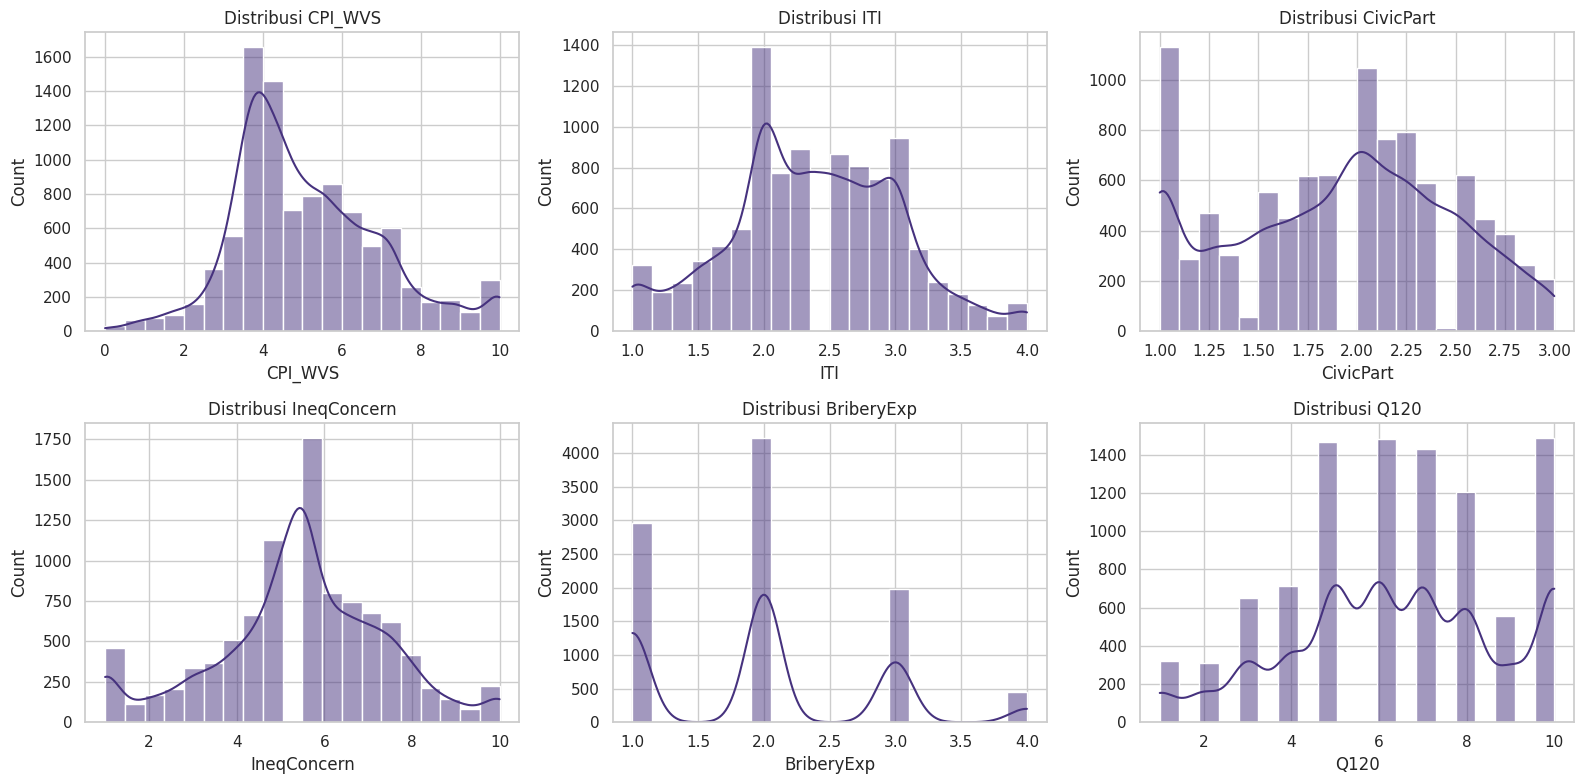

In [ ]:
# =========================================================
# CELL 8: Distribusi Index & Variabel Kunci
# =========================================================
plot_vars = [c for c in ["CPI_WVS","ITI","CivicPart","IneqConcern","BriberyExp","Q120"] if c in df_clean.columns]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, v in zip(axes.flatten(), plot_vars):
    sns.histplot(df_clean[v].dropna(), bins=20, ax=ax, kde=True)
    ax.set_title(f"Distribusi {v}")
for ax in axes.flatten()[len(plot_vars):]:
    ax.set_visible(False)
plt.tight_layout(); plt.show()

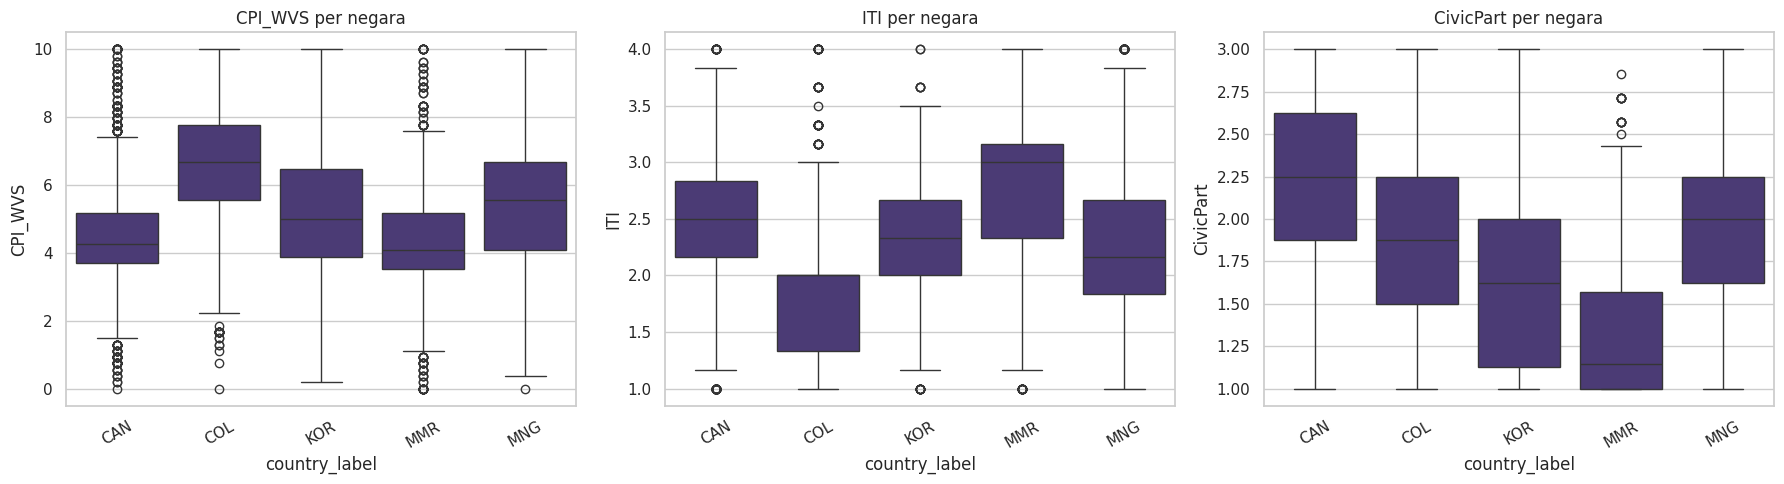

In [ ]:
# =========================================================
# CELL 9: Index per Negara
# =========================================================
plot_vars = [c for c in ["CPI_WVS","ITI","CivicPart"] if c in df_clean.columns]
fig, axes = plt.subplots(1, len(plot_vars), figsize=(6 * len(plot_vars), 5))
for ax, v in zip(axes, plot_vars):
    sns.boxplot(data=df_clean, x="country_label", y=v, ax=ax)
    ax.set_title(f"{v} per negara")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

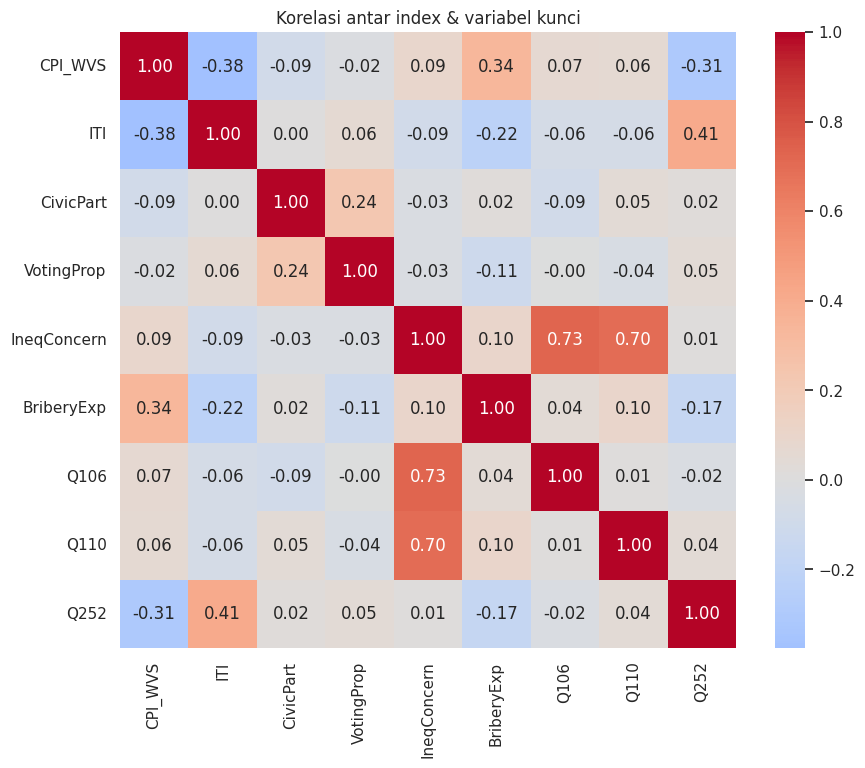

In [ ]:
# =========================================================
# CELL 10: Korelasi Index & Variabel Kunci
# =========================================================
corr_vars = [c for c in ["CPI_WVS","ITI","CivicPart","VotingProp","IneqConcern","BriberyExp","Q106","Q110","Q252"] if c in df_clean.columns]
plt.figure(figsize=(10, 8))
sns.heatmap(df_clean[corr_vars].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Korelasi antar index & variabel kunci")
plt.show()

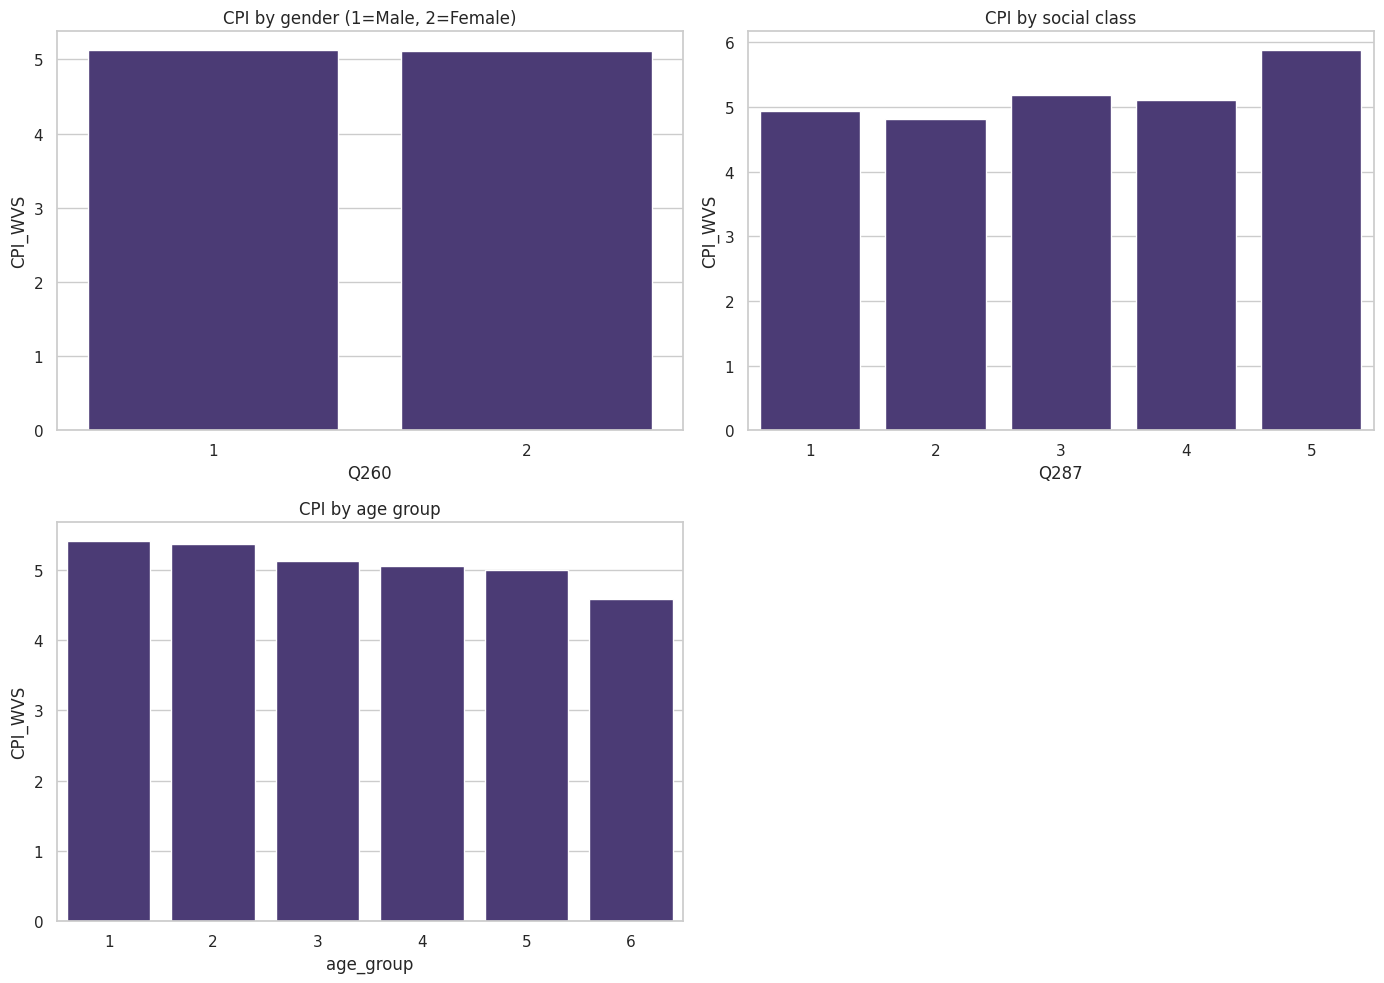

In [ ]:
# =========================================================
# CELL 11: Pola Demografis
# =========================================================
import numpy as np

# Siapkan kolom usia: pakai X003R jika ada, kalau tidak bin Q262
if "X003R" in df_clean.columns:
    df_clean["age_group"] = df_clean["X003R"]
elif "Q262" in df_clean.columns:
    df_clean["age_group"] = pd.cut(
        df_clean["Q262"],
        bins=[15, 24, 34, 44, 54, 64, 120],
        labels=[1, 2, 3, 4, 5, 6]
    ).astype(float)
else:
    df_clean["age_group"] = np.nan

age_label_map = {1:"16-24", 2:"25-34", 3:"35-44", 4:"45-54", 5:"55-64", 6:"65+"}

demo_specs = [
    ("Q260", "CPI by gender (1=Male, 2=Female)"),
    ("H_URBURAL", "CPI by urban/rural"),
    ("Q287", "CPI by social class"),
    ("age_group", "CPI by age group"),
]
demo_specs = [(x, t) for x, t in demo_specs if x in df_clean.columns]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for ax, (x, title) in zip(axes, demo_specs):
    sns.barplot(data=df_clean, x=x, y="CPI_WVS", ax=ax, errorbar=None)
    ax.set_title(title)
for ax in axes[len(demo_specs):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

N untuk clustering: 9511
Fitur: ['CPI_WVS', 'ITI', 'CivicPart', 'IneqConcern', 'OnlineCivic']


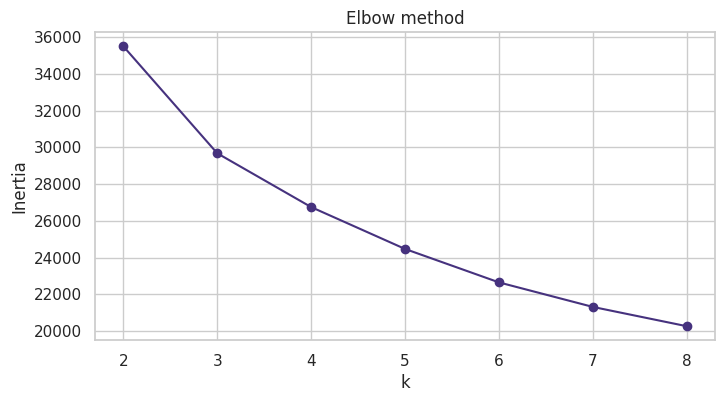

Silhouette: 0.19
         CPI_WVS   ITI  CivicPart  IneqConcern  OnlineCivic     n
cluster                                                          
0           5.85  1.94       2.22         6.38         2.14  2404
1           4.03  2.72       1.39         5.23         1.18  2320
2           7.30  1.86       1.48         5.60         1.24  1696
3           4.12  2.75       2.34         4.84         2.27  3091


In [ ]:
# =========================================================
# CELL 12: Clustering Persona (K-Means)
# =========================================================
cluster_features = [c for c in ["CPI_WVS","ITI","CivicPart","IneqConcern"] if c in df_clean.columns]
if "OnlineCivic" in df_clean.columns:
    cluster_features.append("OnlineCivic")

cluster_df = df_clean[cluster_features].dropna()
print("N untuk clustering:", len(cluster_df))
print("Fitur:", cluster_features)

X_scaled = StandardScaler().fit_transform(cluster_df)

inertia = []
K_range = range(2, 9)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(list(K_range), inertia, marker="o")
plt.title("Elbow method"); plt.xlabel("k"); plt.ylabel("Inertia"); plt.show()

K = 4
km = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10)
labels = km.fit_predict(X_scaled)
silhouette_val = round(silhouette_score(X_scaled, labels), 3)
cluster_K = K
print("Silhouette:", silhouette_val)

cluster_df = cluster_df.assign(cluster=labels)
profile = cluster_df.groupby("cluster")[cluster_features].mean().round(2)
profile["n"] = cluster_df["cluster"].value_counts().sort_index()
print(profile.to_string())

df_clean.loc[cluster_df.index, "persona"] = labels

In [ ]:
# =========================================================
# CELL 13: Klasifikasi Potensi Adopsi
# =========================================================
df_model = df_clean.dropna(subset=["CPI_WVS","CivicPart"]).copy()
df_model["target"] = (
    (df_model["CPI_WVS"] >= df_model["CPI_WVS"].median()) &
    (df_model["CivicPart"] >= df_model["CivicPart"].median())
).astype(int)
print("Distribusi target:", df_model["target"].value_counts(normalize=True).round(3).to_dict())

features = [c for c in ["ITI","IneqConcern","Q106","Q110","Q252","Q260","Q262","Q275","Q288","H_URBURAL"] if c in df_model.columns]
X = df_model[features].fillna(df_model[features].median())
y = df_model["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=df_model["B_COUNTRY"]
)

for name, m in {
    "LogReg": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
}.items():
    m.fit(X_train, y_train)
    auc = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
    print(f"\n{name} ROC-AUC: {auc:.3f}")
    print(classification_report(y_test, m.predict(X_test), digits=2))

Distribusi target: {0: 0.748, 1: 0.252}

LogReg ROC-AUC: 0.682
              precision    recall  f1-score   support

           0       0.76      0.97      0.85      1784
           1       0.56      0.10      0.17       622

    accuracy                           0.75      2406
   macro avg       0.66      0.54      0.51      2406
weighted avg       0.70      0.75      0.67      2406


RandomForest ROC-AUC: 0.671
              precision    recall  f1-score   support

           0       0.77      0.93      0.84      1784
           1       0.49      0.20      0.28       622

    accuracy                           0.74      2406
   macro avg       0.63      0.56      0.56      2406
weighted avg       0.70      0.74      0.70      2406



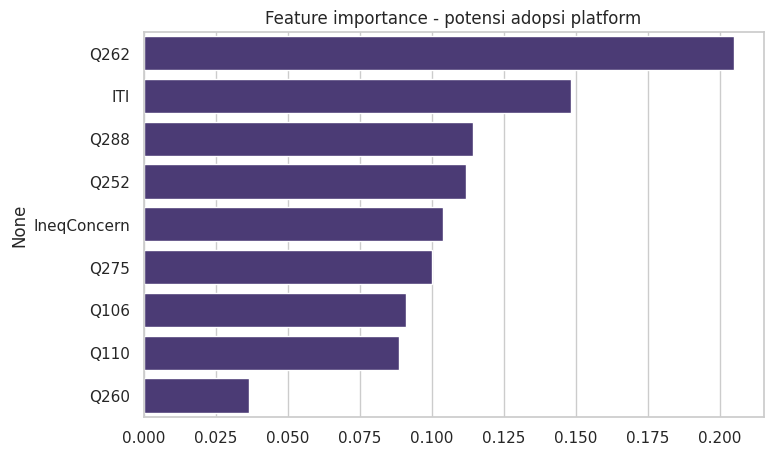

Q262           0.205
ITI            0.148
Q288           0.114
Q252           0.112
IneqConcern    0.104
Q275           0.100
Q106           0.091
Q110           0.089
Q260           0.036


In [ ]:
# =========================================================
# CELL 14: Feature Importance
# =========================================================
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE).fit(X_train, y_train)
imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index)
plt.title("Feature importance - potensi adopsi platform")
plt.show()
print(imp.round(3).to_string())

In [ ]:
# =========================================================
# CELL 15: Ringkasan Insight
# =========================================================
print("=== RINGKASAN INSIGHT ===")
print(f"Negara fokus         : {list(COUNTRY_LABELS.values())}")
print(f"Rata-rata CPI-WVS    : {df_clean['CPI_WVS'].mean():.2f} (0-10, makin tinggi = persepsi korupsi makin buruk)")
print(f"Rata-rata ITI        : {df_clean['ITI'].mean():.2f} (1-4, makin tinggi = makin trust)")
print(f"Rata-rata CivicPart  : {df_clean['CivicPart'].mean():.2f} (1-3, makin tinggi = makin aktif)")

top = df_clean.groupby("country_label")["CPI_WVS"].mean().sort_values(ascending=False)
print(f"Negara CPI tertinggi : {top.index[0]} ({top.iloc[0]:.2f})")
print(f"Negara CPI terendah  : {top.index[-1]} ({top.iloc[-1]:.2f})")

if "persona" in df_clean.columns:
    print("Distribusi persona:")
    print(df_clean["persona"].value_counts().sort_index().to_string())

print(f"Top-3 fitur prediktif: {list(imp.index[:3])}")

=== RINGKASAN INSIGHT ===
Negara fokus         : ['MMR', 'CAN', 'COL', 'KOR', 'MNG']
Rata-rata CPI-WVS    : 5.12 (0-10, makin tinggi = persepsi korupsi makin buruk)
Rata-rata ITI        : 2.38 (1-4, makin tinggi = makin trust)
Rata-rata CivicPart  : 1.92 (1-3, makin tinggi = makin aktif)
Negara CPI tertinggi : COL (6.77)
Negara CPI terendah  : MMR (4.39)
Distribusi persona:
persona
0.0    2404
1.0    2320
2.0    1696
3.0    3091
Top-3 fitur prediktif: ['Q262', 'ITI', 'Q288']
